<img src="logo.png" alt="Vegeta" width="240">

# Kestrel-4Q — a zero-stagger biplane quadrotor tailsitter, and its transitions through the stall

**Kestrel-4Q** is a concept for a small electric UAV that takes off and lands standing on its tail like a quadcopter
and cruises on two wings like an aeroplane. Two straight, equal-span wings sit one above the other with their leading
edges at the **same** station (zero stagger), braced by carbon posts and an X of diagonals; a slim pod between them
carries the battery, the electronics and a forward-looking camera; **four fixed propellers**, one at each wing, all
thrust along the pod's axis — there is no tilt mechanism: the whole aircraft pitches 90° between the hover and the
cruise.

<img src="designs/data/kestrel_concept.webp" alt="Kestrel-4Q concept render" width="640">

*The concept render: appearance and intended operating principle, not a mechanical drawing.*

**The question of this notebook** is the one the concept cannot answer by looking at it: **does it fly through its
transitions?** Going from the hover to the cruise and back, a tailsitter sweeps its angle of attack from 90° to 5° and
back, and between ~11° and ~60° its wing is stalled. Can the four motors, their propellers and the controller hold the
attitude and the height through that stall — forward and back — and with what margin? On the way there, the
specification's own *engineering hold point*: can four fixed, parallel rotors control the aircraft at all?

```
CAD (Dedalus): two wings at one station, pod, truss, nacelles, fin plate, feet ─► layout, clearances, mass table, CG, inertia
Boreas: 9x6 on a 2216 880 KV, 4S ─► full thrust and torque/thrust against the inflow ─► hover, thrust-to-weight
allocation matrix ─► rank per sense of rotation, attainable moments, a motor out, the hover in wind, roll authority
vortex lattice (biplane) + drag build-up ─► neutral point, full-range polar, cruise power, trim by differential thrust
transition model (pitch plane, blown and free-stream spans) ─► hover→cruise and cruise→hover, the matrix, the verdict
Aeromant CFD: the airframe at the transition points with four rotor disks ─► the polar's check ─► the transitions again
plane frame: the truss braced / posts / none ─► stresses, buckling, propeller gap ─► standing on the feet in wind
```

The design modules: `designs/kestrel.py` (CAD and layout), `kestrel_systems.py` (parts, masses, drive tables),
`kestrel_control.py` (the hold point), `kestrel_flight.py` (aerodynamics and cruise), `kestrel_transition.py` (the
transitions), `kestrel_cfd.py` (the CFD and its feedback), `kestrel_structure.py` (truss and ground stance),
`kestrel_drawings.py`; Aeromant's new `aircraft_quad_rotor_disks` template. **Status: concept study** — every number
is an input of this study or a first estimate, none is a validated design value.

In [1]:
# DEBUG: test the notebook end to end before the full run (FEA and CFD mocked). On here or from the shell:
#   VEGETA_DEBUG=1 jupyter nbconvert --to notebook --execute 38_kestrel.ipynb --output 38_kestrel-run.ipynb
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, shutil, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vegeta import dedalus, aeromant
sys.path.insert(0, "designs")
import kestrel, kestrel_systems as ks, kestrel_control as kc, kestrel_flight as kf
import kestrel_transition as kt, kestrel_cfd as kcfd, kestrel_structure as kst, kestrel_drawings as kd

pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 220)
RUNS = Path("_runs/kestrel"); RUNS.mkdir(parents=True, exist_ok=True)
OUT = Path("output/38_kestrel"); OUT.mkdir(parents=True, exist_ok=True)
shutil.copy("designs/kestrel.py", RUNS / "kestrel.py")
design = dedalus.load_design(f"{RUNS / 'kestrel.py'}:Kestrel4Q")
QUICK = os.environ.get("KESTREL_QUICK") == "1"
RUN_CFD = os.environ.get("VEGETA_SKIP_OPENFOAM") != "1"
STATUS = {}
print(f"DEBUG {DEBUG} | QUICK {QUICK} | CFD {'on' if RUN_CFD else 'NOT RUN (VEGETA_SKIP_OPENFOAM=1)'}")
SPEC = pd.Series({"configuration": "electric quadrotor tailsitter, two load-bearing wings", "wings": "zero stagger, equal span, straight",
                  "rotors": "exactly four, fixed, thrust axes parallel to the pod", "take-off mass (this study's target) [kg]": "≤ 2.0",
                  "thrust-to-weight in the hover": "≥ 2", "cruise (survey) [m/s]": f"{kf.V_CRUISE:g}", "endurance at cruise [min]": "≥ 20",
                  "transitions": "both ways, height within 3 m (10 m gain going back), attitude within 10°", "wind for operations [m/s]": "8"},
                 name="Kestrel-4Q — the targets this study sets")
display(SPEC.to_frame())
pd.DataFrame(design.params.table()).set_index("name")

DEBUG False | QUICK False | CFD NOT RUN (VEGETA_SKIP_OPENFOAM=1)


,Kestrel-4Q — the targets this study sets
configuration,"electric quadrotor tailsitter, two load-bearing wings"
wings,"zero stagger, equal span, straight"
rotors,"exactly four, fixed, thrust axes parallel to the pod"
take-off mass (this study's target) [kg],≤ 2.0
thrust-to-weight in the hover,≥ 2
cruise (survey) [m/s],16
endurance at cruise [min],≥ 20
transitions,"both ways, height within 3 m (10 m gain going back), attitude within 10°"
wind for operations [m/s],8


,default,units,min,max,description
name,,,,,
part,aircraft,NaN,NaN,NaN,what to build
span,1000.0,mm,300.00,NaN,span of each wing (both equal)
chord,140.0,mm,40.00,NaN,"chord of each wing (constant, straight wings)"
gap,280.0,mm,80.00,NaN,vertical distance between the wings' chord planes
wing_le_x,200.0,mm,50.00,NaN,"both leading edges, from the nose tip (zero stagger)"
thickness,0.12,,0.06,0.20,NACA thickness ratio
camber,0.0,,0.00,0.06,"NACA camber (0: symmetric, no pitching moment to trim without a tail)"
camber_pos,0.4,,0.10,0.90,
spar_x,0.3,,0.10,0.60,"main spar (and post) station, fraction of chord"


## 1. The aircraft

Both wings are built from one leading-edge station: zero stagger is not a parameter that could drift. The layout's
rules are checked before anything is built: the upper and lower propeller discs clear each other (the gap minus a
diameter), the discs clear the pod, the propeller plane is ahead of the leading edge, the nacelles stay on the wings,
the feet reach aft of the pod.

layout rules: all hold


,volume [cm³],area [cm²],size [mm]
aircraft,14408.107662,14489.84315,540 × 1009 × 632
airframe,14083.496749,11170.215129,540 × 1000 × 632
wing,1607.662884,2841.493742,137 × 1000 × 17
pod,10042.244995,2897.955449,431 × 114 × 283
truss,76.773891,465.825365,8 × 788 × 285
nacelle,139.350725,184.081876,177 × 34 × 34
tail,560.092328,2912.105266,261 × 786 × 632


,span,chord,gap,h,x_le,x_te,x_ac,x_spar,S_wing,S_ref,...,posts,post_length,diagonals,diagonal_length,x_feet,fin_height,ventral_height,fin_tip_chord,fin_root_x,foot_rod_length
"layout [m, m²]",1.0,0.14,0.28,0.14,0.2,0.34,0.235,0.242,0.14,0.28,...,2.0,0.28,4.0,0.4366,0.54,0.19,0.15,0.09,0.28,0.256


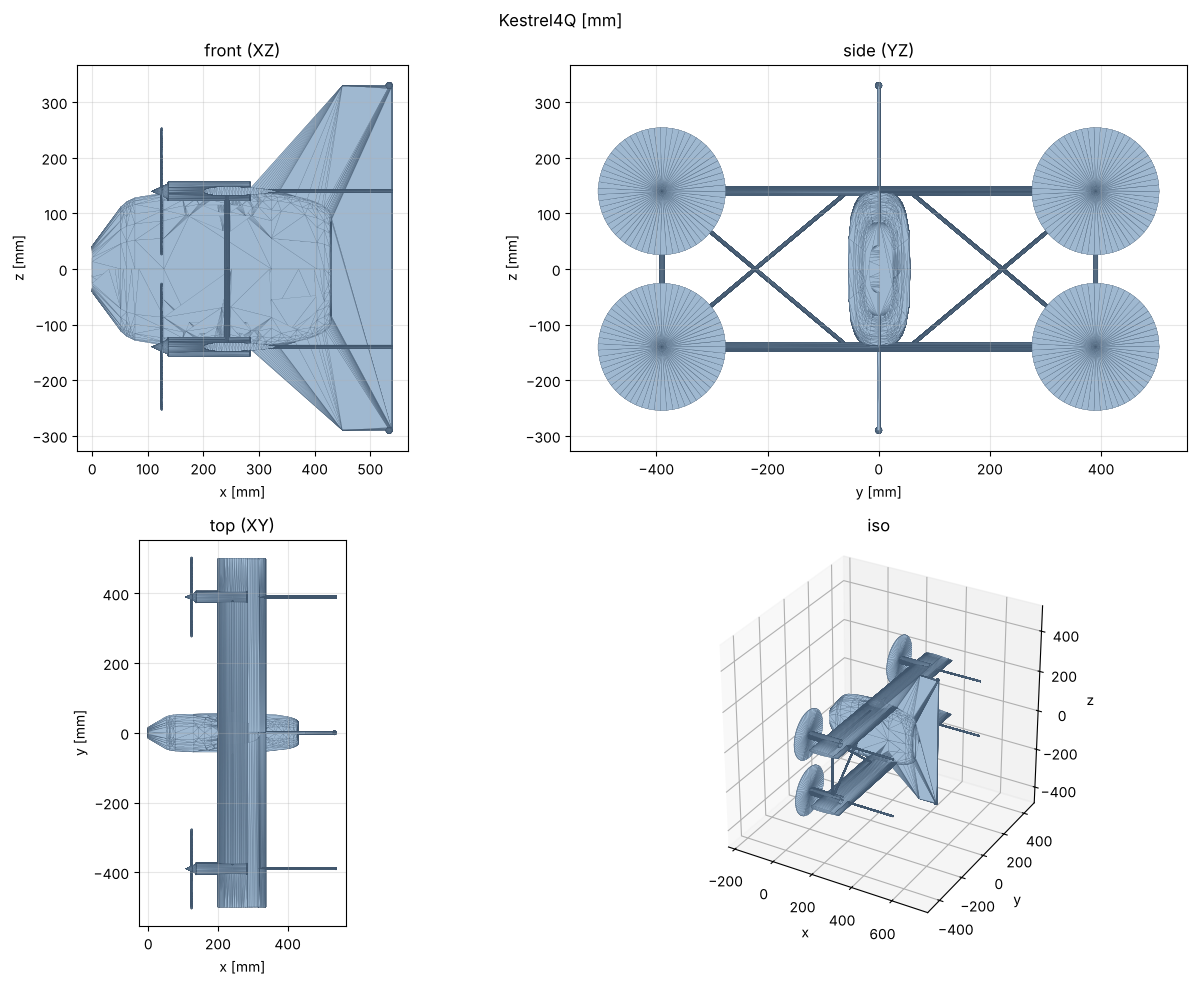

In [3]:
P = design.resolve()
L = kestrel.Kestrel4Q.layout(P)
print("layout rules:", kestrel.Kestrel4Q.checks(P) or "all hold")
parts = {k: design.generate(part=k) for k in ("aircraft", "airframe", "wing", "pod", "truss", "nacelle", "tail")}
cad = {k: g.export(RUNS / "cad" / k, stl_tolerance=0.3) for k, g in parts.items()}
display(pd.DataFrame({k: {"volume [cm³]": (g.measure()["volume"] or 0) / 1e3, "area [cm²]": g.measure()["surface_area"] / 1e2,
                          "size [mm]": " × ".join(f"{d:.0f}" for d in g.measure()["dimensions"])} for k, g in parts.items()}).T)
lay = pd.Series({k: v for k, v in L.items() if isinstance(v, (int, float))}, name="layout [m, m²]")
display(lay.round(4).to_frame().T)
dedalus.plot_views(parts["aircraft"], figsize=(13, 10)); plt.show()

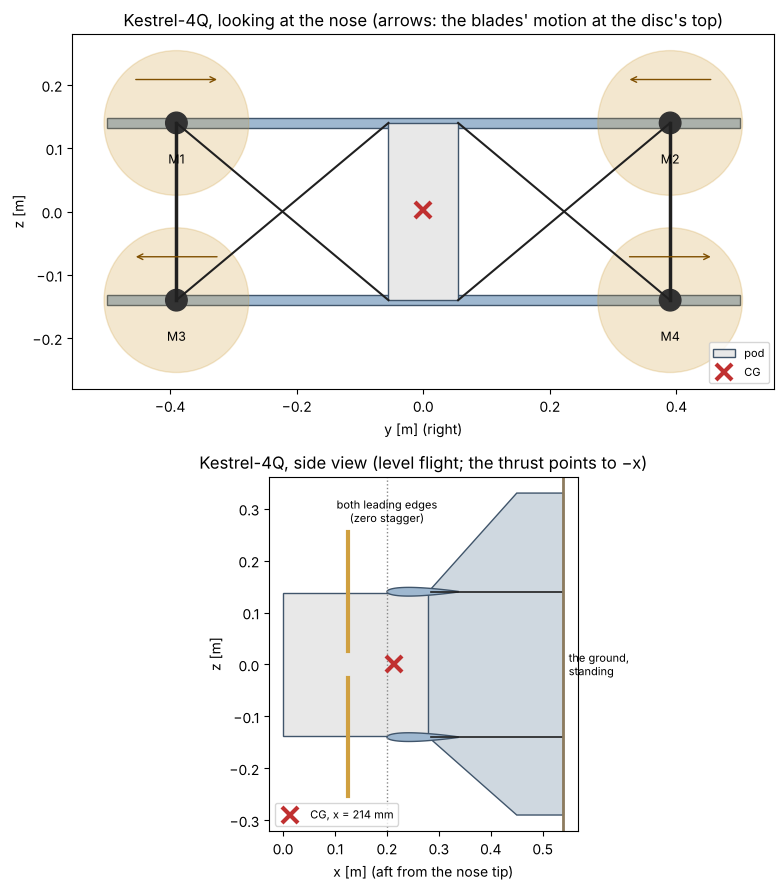

In [4]:
TABLE = ks.mass_table(P)
CI = ks.cg_inertia(TABLE)
fig, ax = plt.subplots(2, 1, figsize=(12, 9))
kd.front_view(P, cg=CI, ax=ax[0]); kd.side_view(P, x_cg=CI["x_cg"], ax=ax[1]); plt.tight_layout(); plt.show()

## 2. Masses, centre of gravity, inertia

The structure from the layout's lengths and areas with assumed densities (balsa-composite wing panels, carbon tubes,
printed joints), the bought parts from `kestrel_systems.COMPONENTS`, a growth margin. The battery slides in the pod to
put the CG 10 % of the chord behind the leading edge — the static margin in section 5 says whether that is right.

In [5]:
mt = pd.DataFrame(TABLE).set_index("item")[["mass_kg", "x", "y", "z", "group"]]
display(mt.assign(mass_g=lambda d: d.mass_kg * 1000).drop(columns="mass_kg").round(3))
grp = pd.Series(ks.groups(TABLE), name="kg")
display(grp.round(3).to_frame().T)
print(f"take-off mass {CI['mass_kg']:.3f} kg; CG x {CI['x_cg'] * 1000:.1f} mm (battery at {CI['battery_x'] * 1000:.0f} mm, "
      f"bay {ks.battery_range(P)[0] * 1000:.0f}-{ks.battery_range(P)[1] * 1000:.0f} mm), z {CI['z_cg'] * 1000:+.1f} mm; "
      f"Ixx {CI['Ixx']:.4f}, Iyy {CI['Iyy']:.4f}, Izz {CI['Izz']:.4f} kg·m²")

,x,y,z,group,mass_g
item,,,,,
motor M1,0.150,-0.390,0.14,propulsion,66.000
propeller M1,0.125,-0.390,0.14,propulsion,14.000
ESC M1,0.220,-0.390,0.14,propulsion,14.000
nacelle M1,0.205,-0.390,0.14,structure,12.000
motor M2,0.150,0.390,0.14,propulsion,66.000
propeller M2,0.125,0.390,0.14,propulsion,14.000
ESC M2,0.220,0.390,0.14,propulsion,14.000
nacelle M2,0.205,0.390,0.14,structure,12.000
motor M3,0.150,-0.390,-0.14,propulsion,66.000


,propulsion,structure,systems,payload,margin
kg,0.736,0.631,0.16,0.105,0.06


take-off mass 1.692 kg; CG x 214.0 mm (battery at 227 mm, bay 160-300 mm), z +2.6 mm; Ixx 0.1049, Iyy 0.0212, Izz 0.0986 kg·m²


## 3. Propulsion

One drive: a 9x6 propeller on a 2216-class 880 KV motor on 4S, through Boreas (BEMT with the generic section, the
motor's first-order model, the battery). The transition model reads three tables against the axial inflow: the full
thrust, the torque-to-thrust ratio κ — the rotor's reaction torque per newton, the **only** lever about the thrust axis
without control surfaces — and the electrical power. Boreas's generic section reads ~25 % low on static thrust: the
control margins below are on the safe side of it.

,thrust_N,rpm,current_A,electrical_W,throttle,figure_of_merit,T_max_N,T_W,kappa_m,total_W
"hover, one drive",4.1491,6722.1749,6.6763,55.4565,0.5612,0.5649,11.9606,2.8827,0.0162,221.8259


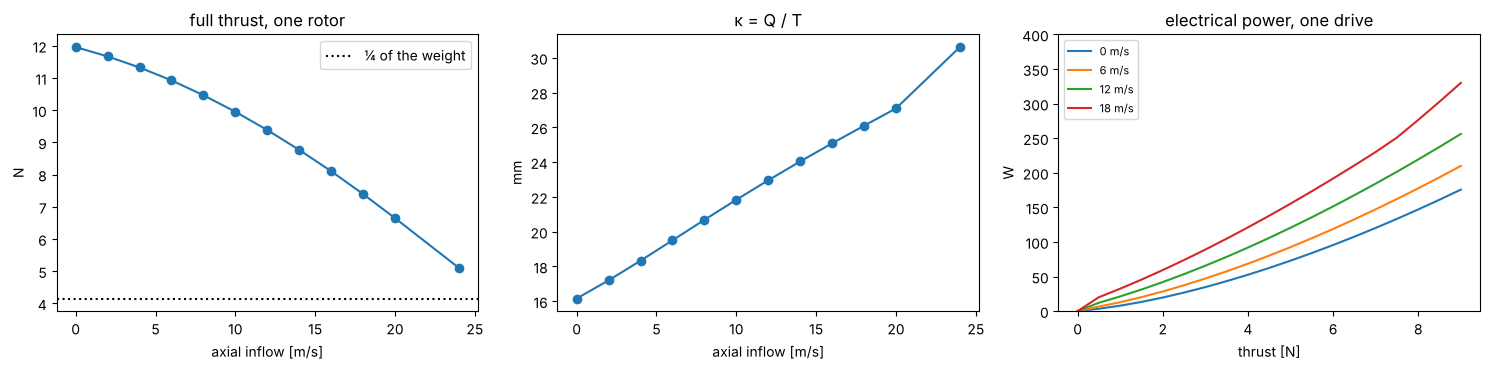

In [6]:
DR = ks.drive_table()
HP = ks.hover_point(CI["mass_kg"])
display(pd.Series(HP, name="hover, one drive").round(4).to_frame().T)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(DR.V, DR.T_max, "o-"); ax[0].axhline(CI["mass_kg"] * ks.G / 4, color="k", ls=":", label="¼ of the weight"); ax[0].set(xlabel="axial inflow [m/s]", ylabel="N", title="full thrust, one rotor"); ax[0].legend()
ax[1].plot(DR.V, np.array(DR.kappa) * 1000, "o-"); ax[1].set(xlabel="axial inflow [m/s]", ylabel="mm", title="κ = Q / T")
for i, v in enumerate(DR.V[::3]):
    j = list(DR.V).index(v)
    ax[2].plot(DR.T, DR.P[j], label=f"{v:g} m/s")
ax[2].set(xlabel="thrust [N]", ylabel="W", title="electrical power, one drive", ylim=(0, 400)); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. The hold point: can four fixed, parallel rotors control it?

The allocation matrix maps the four thrusts to the collective thrust and the three moments about the CG. A rotor at
(dx, y, dz) from the CG pushing toward the nose gives the moment (0, −dz·T, y·T): the **vertical** offset (the gap)
pitches, the **spanwise** offset yaws (in cruise; in the hover it tilts sideways), and a fore–aft offset gives nothing
at all — in a tailsitter the thrust axis is the body axis. The moment about the thrust axis itself (the heading in the
hover, the roll in cruise) only comes from the rotors' reaction torques, ±κ·T. Standing nose-up, the y–z plane is
horizontal and the illustrated 2 × 2 layout is a quadcopter's X seen from above. So the layout is the right one; what
decides is **which way each rotor turns**.

In [7]:
CG = {"x_cg": CI["x_cg"], "y_cg": CI["y_cg"], "z_cg": CI["z_cg"]}
RANK = kc.rank_table(P, kappa=float(DR.kap(0.0)), cg=CG)
display(RANK)
HA = kc.hover_authority(P, mass_kg=CI["mass_kg"], cg=CG, inertia=CI["I"])
display(HA.round(3))
MO = kc.motor_out(P, mass_kg=CI["mass_kg"], cg=CG)
display(MO)
HW = kc.hover_wind(P, mass_kg=CI["mass_kg"], cg=CG)
display(HW.round(2))

,senses (M1..M4),mirror-symmetric,rank,"σ (N, N·m)",condition,never produced,verdict
"diagonal pairs (M1, M4 | M2, M3)","(1, -1, -1, 1)",True,4,"2, 0.78, 0.28, 0.0323",61.906922,—,full control (thrust + 3 moments)
"side columns alike (M1, M3 | M2, M4)","(1, -1, 1, -1)",True,3,"2, 0.781, 0.28, 9.34e-17",inf,-1.00·L + +0.04·N,NOT controllable in the hover
"rows alike (M1, M2 | M3, M4)","(1, 1, -1, -1)",False,3,"2, 0.78, 0.282, 1.3e-17",inf,-0.00·T + -1.00·L + +0.12·M,NOT controllable in the hover
all the same way,"(1, 1, 1, 1)",False,3,"2, 0.78, 0.28, 1.63e-17",inf,-0.02·T + -1.00·L,NOT controllable in the hover


,most negative [N·m],most positive [N·m],inertia [kg·m²],angular acceleration [rad/s²]
about the thrust axis (hover heading / cruise roll),-0.247,0.247,0.105,2.355
about y (pitch-over / cruise pitch),-2.140,2.227,0.021,100.777
about z (hover tilt sideways / cruise yaw),-5.963,5.963,0.099,60.477


,thrusts of the others [N],within limits,unbalanced torque about the axis [N·m],hover
M1 out,"8.45, 8.30, -0.15",True,0.273063,"flies on one diagonal pair (the partner idles): holds thrust and tilt, spins about its..."
M2 out,"8.45, -0.15, 8.30",True,-0.273063,"flies on one diagonal pair (the partner idles): holds thrust and tilt, spins about its..."
M3 out,"8.30, 0.15, 8.14",True,-0.263113,"flies on one diagonal pair (the partner idles): holds thrust and tilt, spins about its..."
M4 out,"0.15, 8.30, 8.14",True,0.263113,"flies on one diagonal pair (the partner idles): holds thrust and tilt, spins about its..."


,wing drag [N],lean into the wind [deg],thrust per rotor [N],T_max per rotor [N],pitch moment left [N·m]
2 m/s,0.82,2.84,4.15,11.96,2.14
4 m/s,3.29,11.22,4.23,11.96,2.18
6 m/s,7.41,24.06,4.54,11.96,2.36
8 m/s,13.17,38.44,5.30,11.96,2.77
10 m/s,20.58,51.12,6.61,11.96,2.93


Only the **diagonal pairing** (M1 and M4 one way, M2 and M3 the other) gives the full rank. The mirror-symmetric
alternative — each side's two rotors turning alike, the "stacked twin" look — makes the reaction-torque row a multiple
of the yaw row: the heading in the hover is lost. The heading lever is the weak one (κ ≈ 16 mm against a half gap of
140 mm and a motor station of 390 mm): ~2 rad/s² of heading acceleration against ~100 rad/s² in pitch. A rotor out in
the hover leaves its diagonal partner idle and an unbalanced torque about the thrust axis: the aircraft can hold its
thrust and tilt while it spins (a reduced-attitude controller), or it needs a parachute — it cannot hold its heading.
Standing in the hover broadside to a wind, the wings are a sail: at 8 m/s it must lean ~40° into it. Turning edge-on
to the wind (yaw) is the operating rule.

## 5. Aerodynamics: the biplane, the drag of the bracing, the polar, the cruise

PEREGRINE's vortex lattice on the two wings at z = ±gap/2 against one of them alone and against a monoplane of the
same span and area — Prandtl's biplane theory puts the induced drag at (1 + σ)/2 of the monoplane's, σ ≈ 0.35 at this
gap/span of 0.28 (the lattice should land near 0.68). The neutral point adds the pod and the four propellers' normal
force ahead of the CG (De Young's blade-element estimate; the momentum bound of a disk turning the whole cross-flow
is shown beside it).

,CLa,k,e,AR,S,x_np,upper share
biplane,4.0784,0.0599,1.4875,3.5714,0.28,0.2331,0.5
one wing alone,4.5576,0.0433,1.0281,7.1429,0.14,0.2437,NaN
"monoplane, same span and area",3.5528,0.0847,1.0522,3.5714,0.28,0.2650,NaN


,lift slope vs two isolated wings,induced drag vs the monoplane,gap / chord,gap / span
biplane factors,0.895,0.707,2.0,0.28


,round tubes [cm²],faired struts [cm²]
wings (2),24.51,24.51
pod (between the wings),7.74,7.74
fin plate,4.09,4.09
nacelles (4),6.44,6.44
posts (2),49.28,5.38
diagonals (4),73.92,8.06
"foot rods (4), axial",0.23,0.23
camera dome,4.07,4.07


Cd0: round 0.0669 (bracing 72 %), faired 0.0238 (bracing 22 %)


,x_np_wings,x_np,Cma_wings,Cma_pod,Cma_props,Cma,static_margin,x_cg
neutral point,0.2331,0.2284,-0.5551,0.0608,0.064,-0.4302,0.1029,0.214


propellers' normal force slope at 16 m/s: estimate 4.5 N/rad, momentum bound 53.0 N/rad


,cl_alpha,cd0,k,cl_max,cd90,alpha0,width,source
polar,4.07843,0.066896,0.066573,0.81,1.238571,0.0,0.02618,model


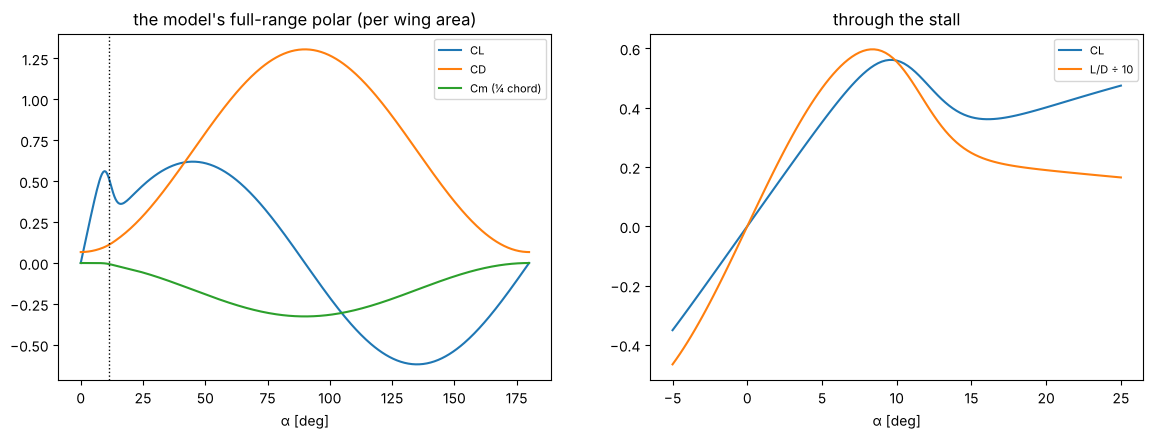

In [8]:
A = kf.aero(P)
display(pd.DataFrame({k: v for k, v in A.items() if k != "factors"}).T.round(4))
display(pd.Series(A["factors"], name="biplane factors").round(3).to_frame().T)
D_round, D_faired = kf.drag_buildup(P), kf.drag_buildup(P, faired=True)
dtab = pd.DataFrame({"round tubes": D_round["parts_m2"], "faired struts": D_faired["parts_m2"]}) * 1e4
display(dtab.round(2).rename(columns=lambda c: c + " [cm²]"))
print(f"Cd0: round {D_round['Cd0']:.4f} (bracing {D_round['bracing_share'] * 100:.0f} %), faired {D_faired['Cd0']:.4f} (bracing {D_faired['bracing_share'] * 100:.0f} %)")
NP = kf.neutral_point(P, x_cg=CI["x_cg"], a=A)
display(pd.Series(NP, name="neutral point").round(4).to_frame().T)
print(f"propellers' normal force slope at 16 m/s: estimate {kf.prop_normal_force_slope(16, 0.8, P):.1f} N/rad, momentum bound {kf.prop_normal_force_slope(16, 0.8, P, bound=True):.1f} N/rad")
POL = kf.polar(P, a=A)
display(pd.Series(POL.__dict__, name="polar").to_frame().T)
kd.polar_figure(POL); plt.show()

round tubes


,CL,feasible,note,α [deg],L/D,drag [N],Cm about CG,upper rotor [N],lower rotor [N],trim by thrust,electrical [W],endurance [min],range [km]
V [m/s],,,,,,,,,,,,,
9.0,1.195,False,beyond the wing's CL max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10.0,0.968,False,beyond the wing's CL max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11.0,0.800,True,the upper pair below T_min: thrust alone cannot trim,11.236,7.305,2.272,-0.082,0.151,0.985,False,58.560,40.033,26.422
12.0,0.672,True,the upper pair below T_min: thrust alone cannot trim,9.441,6.931,2.395,-0.069,0.183,1.015,False,64.881,36.132,26.015
13.0,0.573,True,the upper pair below T_min: thrust alone cannot trim,8.044,6.454,2.572,-0.059,0.228,1.058,False,73.365,31.954,24.924
14.0,0.494,True,,6.936,5.940,2.794,-0.051,0.284,1.113,True,83.611,28.038,23.552
15.0,0.430,True,,6.042,5.430,3.057,-0.044,0.351,1.177,True,96.270,24.352,21.916
16.0,0.378,True,,5.311,4.947,3.355,-0.039,0.427,1.250,True,110.952,21.129,20.284
17.0,0.335,True,,4.704,4.503,3.686,-0.034,0.511,1.331,True,128.210,18.285,18.651


faired struts


,CL,feasible,note,α [deg],L/D,drag [N],Cm about CG,upper rotor [N],lower rotor [N],trim by thrust,electrical [W],endurance [min],range [km]
V [m/s],,,,,,,,,,,,,
9.0,1.195,False,beyond the wing's CL max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10.0,0.968,False,beyond the wing's CL max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11.0,0.800,True,the upper pair below T_min: thrust alone cannot trim,11.236,12.052,1.377,-0.082,-0.076,0.765,False,44.269,52.956,34.951
12.0,0.672,True,the upper pair below T_min: thrust alone cannot trim,9.441,12.482,1.330,-0.069,-0.089,0.753,False,46.439,50.481,36.346
13.0,0.573,True,the upper pair below T_min: thrust alone cannot trim,8.044,12.556,1.322,-0.059,-0.091,0.751,False,49.237,47.613,37.138
14.0,0.494,True,the upper pair below T_min: thrust alone cannot trim,6.936,12.342,1.345,-0.051,-0.085,0.757,False,52.335,44.795,37.627
15.0,0.430,True,the upper pair below T_min: thrust alone cannot trim,6.042,11.917,1.393,-0.044,-0.072,0.769,False,56.050,41.826,37.643
16.0,0.378,True,the upper pair below T_min: thrust alone cannot trim,5.311,11.356,1.462,-0.039,-0.055,0.786,False,60.045,39.043,37.481
17.0,0.335,True,the upper pair below T_min: thrust alone cannot trim,4.704,10.719,1.548,-0.034,-0.033,0.807,False,64.688,36.240,36.965


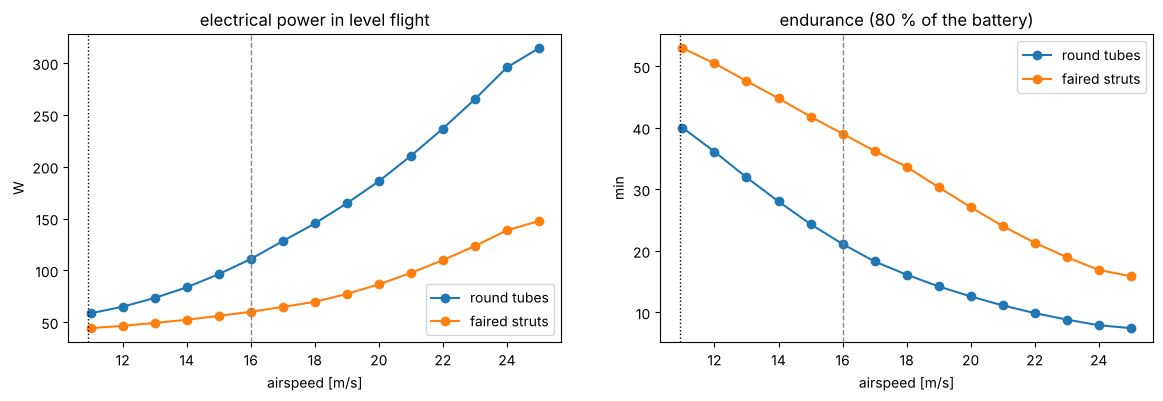

,torque lever [N·m],ailerons [N·m],ratio,aileron span per side [m]
V,,,,
12.0,0.422,2.169,5.134,0.224
16.0,0.394,3.914,9.932,0.224
20.0,0.347,6.197,17.879,0.224


In [9]:
CRU = {"round tubes": kf.cruise(P, mass_kg=CI["mass_kg"], x_cg=CI["x_cg"], z_cg=CI["z_cg"], pol=POL),
       "faired struts": kf.cruise(P, mass_kg=CI["mass_kg"], x_cg=CI["x_cg"], z_cg=CI["z_cg"], pol=kf.polar(P, a=A, faired=True))}
for k, c in CRU.items():
    print(k); display(c.round(3))
VS = kf.stall_speed(P, mass_kg=CI["mass_kg"], pol=POL)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, c in CRU.items():
    c = c[c["feasible"]]
    ax[0].plot(c.index, c["electrical [W]"], "o-", label=k); ax[1].plot(c.index, c["endurance [min]"], "o-", label=k)
for a_ in ax:
    a_.axvline(VS, color="k", ls=":", lw=1); a_.axvline(kf.V_CRUISE, color="#888", ls="--", lw=1); a_.set_xlabel("airspeed [m/s]"); a_.legend()
ax[0].set(ylabel="W", title="electrical power in level flight"); ax[1].set(ylabel="min", title="endurance (80 % of the battery)")
plt.show()
RA = pd.DataFrame([kc.roll_authority(P, V=v, thrust_each=float(CRU["round tubes"].loc[v, "upper rotor [N]"]), cl_alpha_3d=POL.cl_alpha)
                   for v in (12.0, 16.0, 20.0)]).set_index("V")
display(RA.round(3))

The trim: with a symmetric section and no tail, the moment about the CG at a positive lift is nose-down by the
static margin; the lower pair pushes harder than the upper to hold the nose up. Where the upper pair would have to
drop below idle, thrust alone cannot trim — the elevons (trailing-edge surfaces on the blown outer panels) do it.
The roll in cruise: the rotors' reaction torque is a weak lever; ailerons on the blown panels are an order of
magnitude stronger. Both point the same way: the minimal concept needs **elevons** on the outer panels.

## 6. The transitions — hover to cruise and back, through the stall

`kestrel_transition` flies the aircraft in the vertical plane (x, z, pitch). Each wing is split into the span blown
by its two propellers and the rest: the slipstream adds a velocity Δv along the body axis, so the blown span sees a
much smaller angle of attack and a larger dynamic pressure than the free stream. The controller knows nothing of the
aerodynamic moment: a pitch schedule, a PID on pitch with gains scheduled on the airspeed, the height held with the
collective (a vertical-speed command limited to +3 / −2 m/s), the moment allocated to the differential thrust and the
elevons, the collective giving way when the rotors saturate. Roll is checked along the trajectory: the rolling
moment of one side's free-stream panels stalling first, against what the rotors and the elevons have left.

First the nominal pair: 3 s pitch schedules, still air.

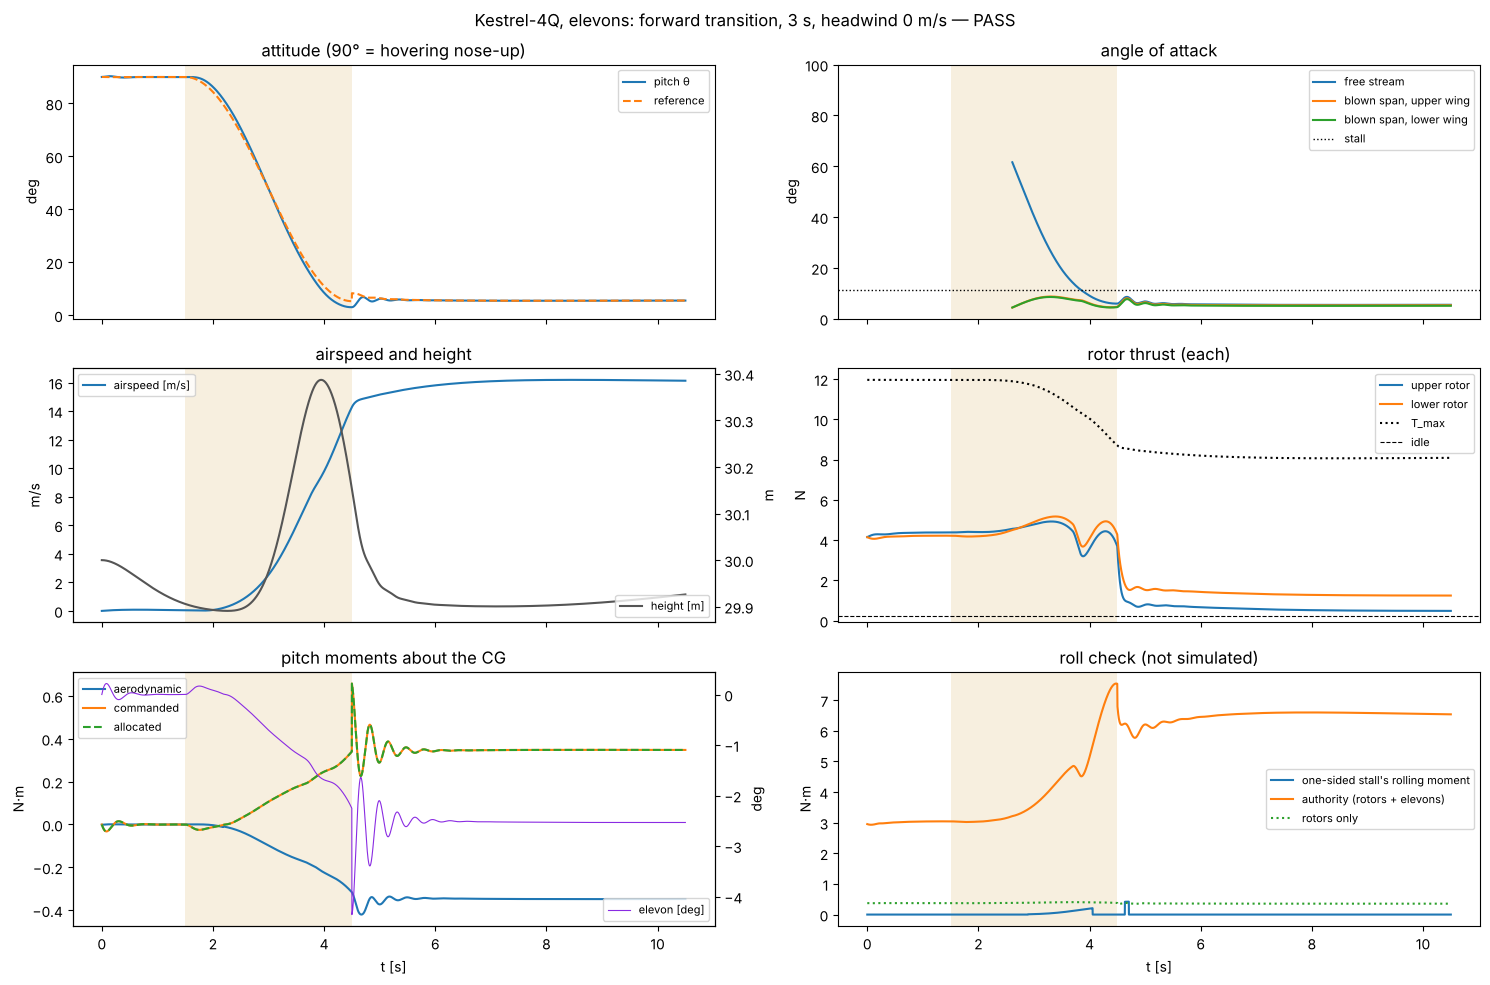

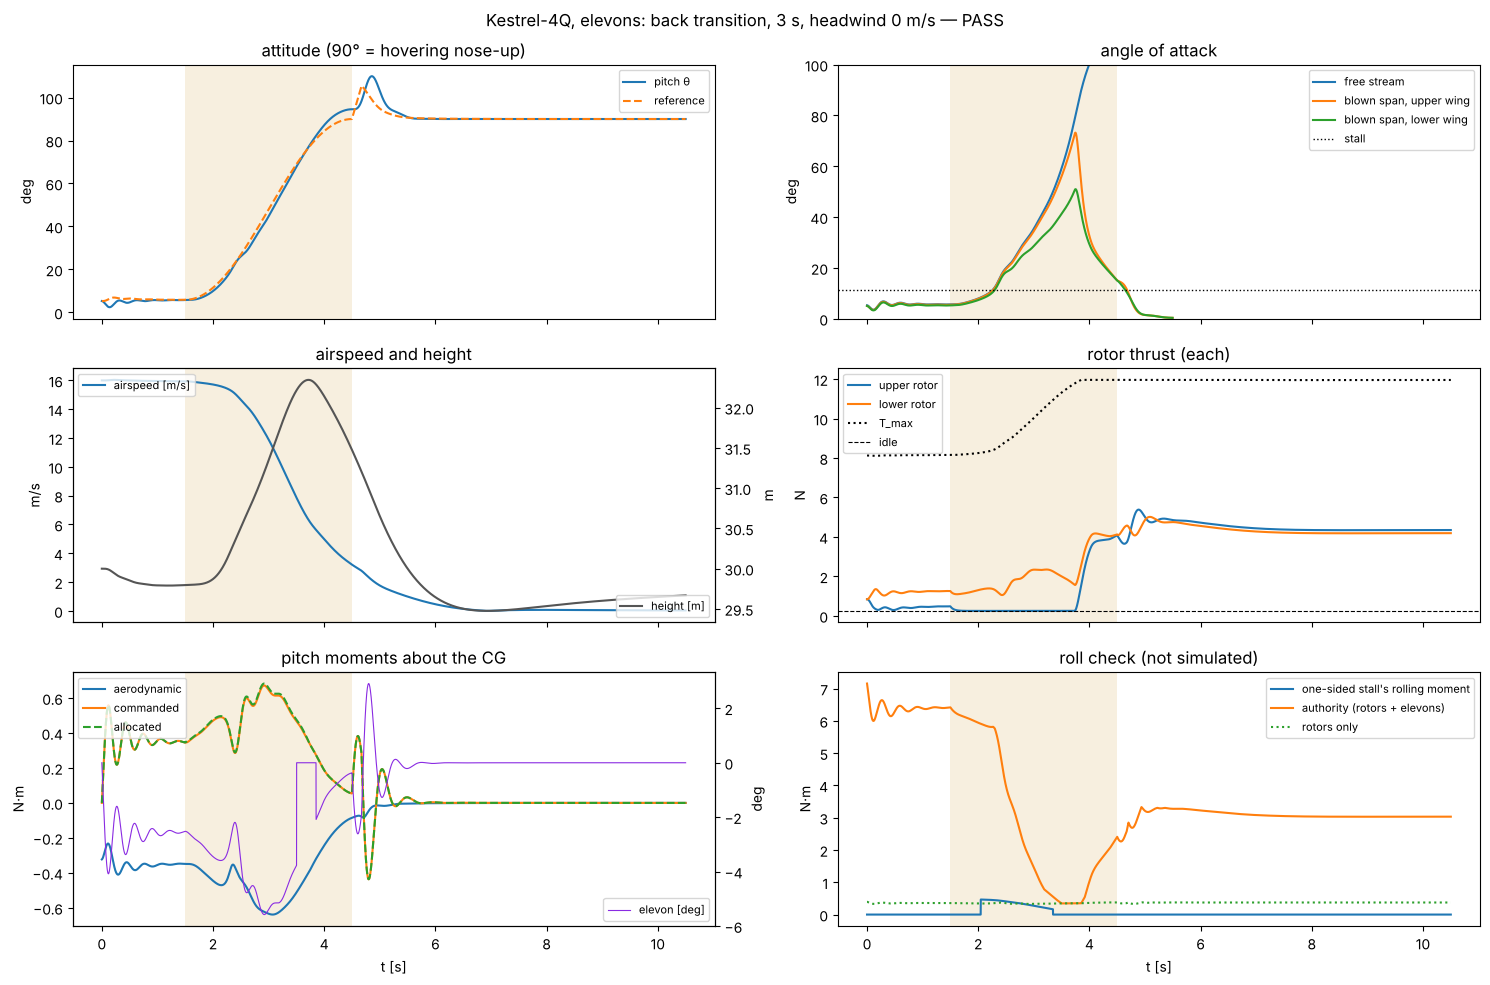

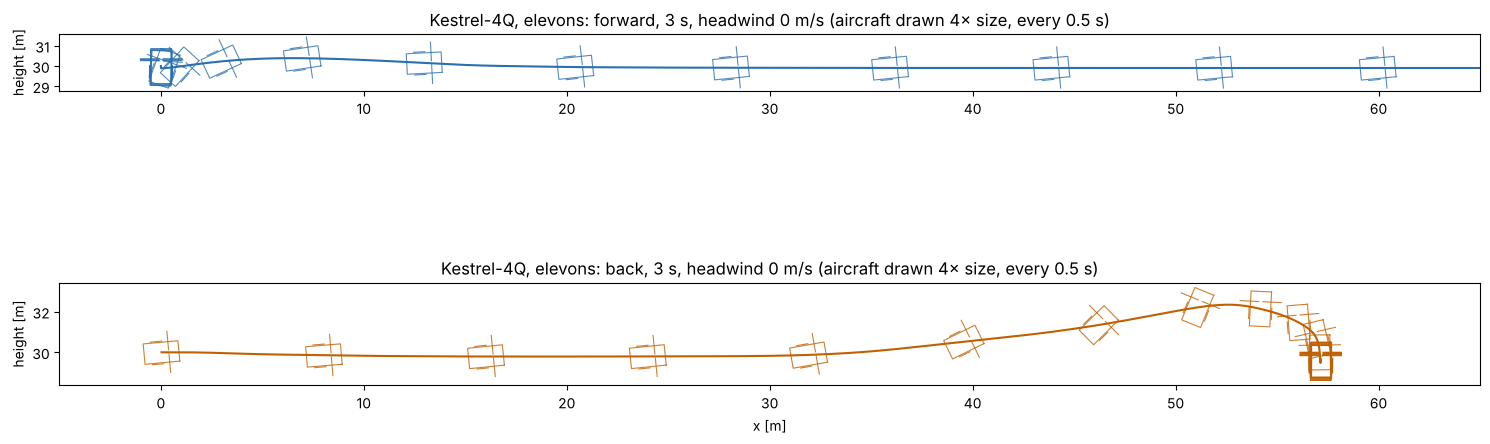

,height loss [m],height gain [m],pitch error max [deg],α free-stream max in transition [deg],"time stalled, free stream [s]",α blown max while stalled [deg],moment shortfall [s],collective given way [s],least pitch margin,peak rotor thrust / T_max,...,roll demand / rotors' authority,speed at the end [m/s],distance [m],energy [Wh],duration [s],hover reached at [s],holds height,holds attitude,roll holds,pass
forward,0.10898,0.387105,2.512361,46.080722,0.952,8.746836,0.0,0.0,0.831235,0.536562,...,1.126098,16.126264,108.464669,0.535898,10.5,NaN,True,True,True,True
back,0.524424,2.345667,4.55248,122.716877,1.488,73.231528,0.0,2.28,0.77783,0.450116,...,1.359843,0.03742,57.11183,0.530358,10.5,5.962,True,True,True,True


In [10]:
VEH = kt.make_vehicle(P, aero=A, name="Kestrel-4Q, elevons")
NOM = {k: kt.simulate(VEH, k, t_tr=3.0) for k in ("forward", "back")}
for ep in NOM.values():
    kd.episode_figure(ep, VEH); plt.show()
kd.path_figure(list(NOM.values()), VEH, x_max=65); plt.show()
display(pd.DataFrame({k: ep.metrics for k, ep in NOM.items()}).T)

**The matrix.** Three vehicles — the baseline with elevons, the same with the rotors as the only effectors (the
minimal concept of the specification), and the heavy one (2.0 kg: a 0.3 kg payload at the quarter chord, the CG
moved aft) — both directions, three schedule lengths, still air and a 6 m/s headwind. Then a 3 m/s vertical gust in
the middle of the pitch schedule.

In [11]:
VEHICLES = {"elevons": VEH, "rotors only": kt.make_vehicle(P, aero=A, elevons=False, name="Kestrel-4Q, rotors only"),
            "2.0 kg, CG aft": kt.make_vehicle(P, aero=A, extra_kg=0.3, name="Kestrel-4Q, 2.0 kg")}
print({k: f"{v.mass:.2f} kg, CG {v.x_cg * 1000:.0f} mm, static margin {kf.neutral_point(P, x_cg=v.x_cg, a=A)['static_margin']:.3f}" for k, v in VEHICLES.items()})
durs = (1.5, 3.0) if QUICK else (1.5, 3.0, 5.0)
MAT, EPS = kt.matrix(VEHICLES, durations=durs, headwinds=(0.0, 6.0), progress=True)
cols = ["height loss [m]", "height gain [m]", "pitch error max [deg]", "time stalled, free stream [s]", "α blown max while stalled [deg]",
        "moment shortfall [s]", "least pitch margin", "peak rotor thrust / T_max", "elevon max [deg]", "roll demand / authority",
        "roll demand / rotors' authority", "pass"]
display(MAT[cols].astype({c: float for c in cols if c != "pass"}).round(2))
VER = kt.verdict(MAT)
for k, v in VER.items():
    print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
MAT.to_csv(OUT / "transition_matrix.csv")

{'elevons': '1.69 kg, CG 214 mm, static margin 0.103', 'rotors only': '1.69 kg, CG 214 mm, static margin 0.103', '2.0 kg, CG aft': '1.99 kg, CG 217 mm, static margin 0.080'}


transitions:   0%|          | 0/36 [00:00<?, ?it/s]

height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  α blown max while stalled [deg]  moment shortfall [s]  least pitch margin  \
vehicle        direction t_tr [s] headwind [m/s]                                                                                                                                                                      
elevons        forward   1.5      0.0                        3.32             0.25                   7.80                           0.28                             5.40                  0.00                0.76   
                                  6.0                        0.32             0.08                   4.48                           1.12                            18.82                  0.00                0.84   
                         3.0      0.0                        0.11             0.39                   2.51                           0.95                             8.75                  0.00                0.83   
                                  6.0                        0.48             0.09                   1.91                           2.50                            18.91                  0.00                0.81   
                         5.0      0.0                        1.17             0.37                   1.55                           2.56                            14.87                  0.00                0.77   
                                  6.0                        1.48             0.44                   1.31                           4.48                            20.37                  0.00                0.80   
               back      1.5      0.0                        0.29             1.48                   7.18                           0.97                            75.53                  0.00                0.68   
                                  6.0                        0.21             1.48                   7.18                           0.97                            75.53                  0.00                0.68   
                         3.0      0.0                        0.52             2.35                   4.55                           1.49                            73.23                  0.00                0.78   
                                  6.0                        0.21             2.35                   4.55                           1.49                            73.23                  0.00                0.78   
                         5.0      0.0                        0.86             3.23                   2.33                           1.84                            60.61                  0.00                0.84   
                                  6.0                        0.44             3.23                   2.33                           1.84                            60.61                  0.00                0.84   
rotors only    forward   1.5      0.0                        0.83             0.25                   8.17                           0.27                             5.36                  0.02                0.00   
                                  6.0                        0.19             0.14                   4.39                           1.10                            18.61                  0.00                0.72   
                         3.0      0.0                        0.11             0.43                   2.49                           0.92                             8.58                  0.00                0.77   
                                  6.0                        0.22             0.14                   1.98                           2.45                            18.69                  0.00                0.75   
                         5.0      0.0                        0.72             0.41                   1.71                           2.45                            14.52           

2.0 kg, CG aft: 11 of 12 pass
   - forward 1.5 s, headwind 0 m/s: fails holds height, holds attitude
elevons: 11 of 12 pass
   - forward 1.5 s, headwind 0 m/s: fails holds height
rotors only: 3 of 12 pass
   - forward 1.5 s, headwind 0 m/s: fails roll holds
   - forward 1.5 s, headwind 6 m/s: fails roll holds
   - forward 5 s, headwind 6 m/s: fails roll holds
   - back 1.5 s, headwind 0 m/s: fails roll holds
   - back 1.5 s, headwind 6 m/s: fails roll holds
   - back 3 s, headwind 0 m/s: fails roll holds
   - back 3 s, headwind 6 m/s: fails roll holds
   - back 5 s, headwind 0 m/s: fails roll holds
   - back 5 s, headwind 6 m/s: fails roll holds


In [12]:
GUST = {(k, g): kt.simulate(VEH, k, t_tr=3.0, gust_up=g) for k in ("forward", "back") for g in (3.0, -3.0)}
display(pd.DataFrame({f"{k}, gust {g:+g} m/s": ep.metrics for (k, g), ep in GUST.items()}).T[cols])

,height loss [m],height gain [m],pitch error max [deg],"time stalled, free stream [s]",α blown max while stalled [deg],moment shortfall [s],least pitch margin,peak rotor thrust / T_max,elevon max [deg],roll demand / authority,roll demand / rotors' authority,pass
"forward, gust +3 m/s",0.10898,0.366792,2.4382,0.728,18.505949,0.0,0.832787,0.539714,4.316136,0.068913,1.124934,True
"forward, gust -3 m/s",0.195832,0.099962,2.958531,0.718,9.721499,0.0,0.842592,0.578515,4.051213,0.041596,0.544565,True
"back, gust +3 m/s",0.756056,3.286647,5.127384,1.566,72.324824,0.0,0.697674,0.416493,7.581771,0.341189,1.359843,True
"back, gust -3 m/s",0.377028,1.615905,4.605744,1.426,71.671605,0.0,0.782171,0.441656,5.468047,0.311101,1.359843,True


**The back transition's strategies.** Pitching up from the cruise, the wing first lifts the aircraft (the balloon);
the height loop then cuts the thrust, the slipstream fades, the blown span stalls with the rest and the rotors near
idle have little room for torque. Two remedies: slow down first (enter at 13 m/s instead of 16), or keep a floor
under the collective through the pitch schedule (half the hover thrust).

In [13]:
STRAT = {}
for ve in (16.0, 13.0):
    for fl in (0.0, 0.5):
        for el, veh in (("elevons", VEH), ("rotors only", VEHICLES["rotors only"])):
            STRAT[(el, ve, fl)] = kt.simulate(veh, "back", t_tr=3.0, V_entry=ve, floor=fl).metrics
ST = pd.DataFrame(STRAT).T
ST.index.names = ["effectors", "entry speed [m/s]", "collective floor"]
display(ST[cols])

,,,height loss [m],height gain [m],pitch error max [deg],"time stalled, free stream [s]",α blown max while stalled [deg],moment shortfall [s],least pitch margin,peak rotor thrust / T_max,elevon max [deg],roll demand / authority,roll demand / rotors' authority,pass
effectors,entry speed [m/s],collective floor,,,,,,,,,,,,
elevons,16.0,0.0,0.524424,2.345667,4.55248,1.488,73.231528,0.0,0.77783,0.450116,5.578481,0.29533,1.359843,True
rotors only,16.0,0.0,1.603676,5.624066,4.401826,1.498,72.352627,0.0,0.661917,0.492761,0.0,1.803368,1.803368,False
elevons,16.0,0.5,0.210009,11.487927,3.918742,1.972,33.502007,0.0,0.795386,0.362734,5.328908,0.132694,1.785535,False
rotors only,16.0,0.5,0.130182,16.104742,3.343221,1.778,27.194266,0.0,0.604244,0.53708,0.0,2.494087,2.494087,False
elevons,13.0,0.0,0.741543,0.099715,4.274213,1.878,42.911123,0.0,0.801615,0.418683,5.144155,0.227492,0.900324,True
rotors only,13.0,0.0,0.240629,0.942681,4.32604,1.51,60.333844,0.0,0.742066,0.434187,0.0,1.052961,1.052961,False
elevons,13.0,0.5,1.278954,4.779363,4.263483,1.916,41.706419,0.0,0.799568,0.419251,5.215499,0.175821,1.138147,True
rotors only,13.0,0.5,2.033339,7.496895,4.062131,1.948,37.276171,0.0,0.742066,0.421556,0.0,1.365298,1.365298,False


## 7. The transitions in CFD

The polar of section 5 is an estimate: attached flow blended into a flat plate, the slipstream from momentum theory,
each wing part on its own. At the points the aircraft actually flies — from the nominal transitions, the first time
the free-stream angle of attack passes 80, 60, 45, 30, 20, 15 and 10° going forward and coming back, plus the hover —
Aeromant solves the airframe in steady RANS (k-ω SST) with the **four propellers as rotor disks** at the rpm Boreas
gives for each pair's thrust at that inflow (`aircraft_quad_rotor_disks`). The bare airframe from 0 to 90° at 10 m/s
is the reference stall. Solved, the CFD's coefficients minus the model's at the same points become a correction the
transition model adds to its airframe forces, and the transitions are flown again. Without OpenFOAM the cases are
prepared and listed as NOT RUN (`VEGETA_SKIP_OPENFOAM=1`).

In [14]:
PTS = kcfd.points(list(NOM.values()), mass_kg=VEH.mass)
CSPEC = kcfd.specs(PTS, sweep=not QUICK)
CFDT = kcfd.not_run_table(CSPEC)
CFD_SOLVED = False
if RUN_CFD:
    try:
        CASES = kcfd.plan(RUNS / "cfd", PTS, x_cg_m=VEH.x_cg, z_cg_m=VEH.z_cg, sweep=not QUICK)
        names = list(CASES)
        res = aeromant.run_cases([CASES[n] for n in names], jobs=1, processors=4, progress=True, cache=True)
        CFDT = kcfd.table(dict(zip(names, res)), CSPEC)
        CFD_SOLVED = bool((CFDT["status"] == "solved").any())
    except Exception as exc:                                   # no OpenFOAM, no CAD kernel: the plan stays NOT RUN
        print("CFD not run:", exc)
STATUS["CFD"] = "run" if CFD_SOLVED else "NOT RUN"
display(CFDT)
CFDT.to_csv(OUT / "cfd_cases.csv")

,status,α [deg],V [m/s],source,template,rpm upper,rpm lower,Re (chord)
"forward 3 s: α 53°, 1.5 m/s, T 4.63/4.64 N",NOT RUN,52.8861,1.50599,forward 3 s,aircraft_quad_rotor_disks,7154.278796,7162.626367,14440.998168
"forward 3 s: α 45°, 2.1 m/s, T 4.73/4.80 N",NOT RUN,44.998494,2.095608,forward 3 s,aircraft_quad_rotor_disks,7266.827155,7324.45689,20094.869133
"forward 3 s: α 30°, 3.8 m/s, T 4.91/5.11 N",NOT RUN,29.934512,3.832142,forward 3 s,aircraft_quad_rotor_disks,7554.46285,7701.238622,36746.570799
"forward 3 s: α 20°, 5.8 m/s, T 4.85/5.14 N",NOT RUN,19.948691,5.824897,forward 3 s,aircraft_quad_rotor_disks,7750.745778,7960.240233,55855.178061
"forward 3 s: α 15°, 7.3 m/s, T 4.54/4.88 N",NOT RUN,14.964813,7.345324,forward 3 s,aircraft_quad_rotor_disks,7743.645352,7992.261967,70434.612055
"forward 3 s: α 10°, 9.3 m/s, T 3.29/3.79 N",NOT RUN,9.985109,9.312609,forward 3 s,aircraft_quad_rotor_disks,7127.179169,7523.868328,89298.98813
"back 3 s: α 80°, 6.1 m/s, T 0.29/1.58 N",NOT RUN,80.069949,6.134746,back 3 s,aircraft_quad_rotor_disks,1891.768082,4209.297301,58826.336168
"back 3 s: α 60°, 7.8 m/s, T 0.25/1.98 N",NOT RUN,60.063531,7.77732,back 3 s,aircraft_quad_rotor_disks,2387.113904,5002.753806,74577.044311
"back 3 s: α 45°, 10.0 m/s, T 0.25/2.35 N",NOT RUN,45.013034,10.013281,back 3 s,aircraft_quad_rotor_disks,3215.369433,5893.257758,96017.760307
"back 3 s: α 30°, 13.0 m/s, T 0.25/2.02 N",NOT RUN,30.015775,13.038355,back 3 s,aircraft_quad_rotor_disks,4482.32687,6477.280313,125025.325543


In [15]:
if CFD_SOLVED:
    CORR = kcfd.CFDAirframe.from_results(CFDT, VEH)
    cmp_rows = {}
    for s in CORR.samples:
        cmp_rows[f"α {math.degrees(s['alpha']):.0f}°, μ {s['mu']:.2f}"] = {"ΔCL": s["dCL"], "ΔCD": s["dCD"], "ΔCm": s["dCm"]}
    display(pd.DataFrame(cmp_rows).T.round(3))
    VEH_CFD = kt.make_vehicle(P, aero=A, airframe=CORR, name="Kestrel-4Q, elevons, CFD aero")
    VEHR_CFD = kt.make_vehicle(P, aero=A, airframe=CORR, elevons=False, name="Kestrel-4Q, rotors only, CFD aero")
    MAT_CFD, EPS_CFD = kt.matrix({"elevons, CFD": VEH_CFD, "rotors only, CFD": VEHR_CFD}, durations=durs, headwinds=(0.0, 6.0), progress=True)
    display(MAT_CFD[cols])
    VER_CFD = kt.verdict(MAT_CFD)
    for k, v in VER_CFD.items():
        print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
    kd.polar_figure(POL, CFDT); plt.show()
else:
    VER_CFD = None
    print("The transitions above fly on the model's polar: the CFD check is NOT RUN. Run this notebook where OpenFOAM is "
          "installed (the cases are prepared by kestrel_cfd.plan) and these cells fly the matrix again on the CFD's aerodynamics.")

The transitions above fly on the model's polar: the CFD check is NOT RUN. Run this notebook where OpenFOAM is installed (the cases are prepared by kestrel_cfd.plan) and these cells fly the matrix again on the CFD's aerodynamics.


## 8. The truss, the propellers' gap under load, standing on the feet

The front view as a plane frame at a 4 g pull-up: the spars as beams through the pod (clamped there), the posts and
diagonals as pin-ended bars, the lift elliptic, less the wings' and the motors' inertia. Braced (posts and X), posts
only, no truss — and once more with the upper wing carrying 75 % of the lift (one wing stalling first). Then the
aircraft standing nose-up on its six feet: tip-over angles, the wind that tips it over, the touchdown.

In [16]:
BR = {"even lift": kst.compare_bracing(P, mass_kg=CI["mass_kg"]), "upper wing 75 %": kst.compare_bracing(P, mass_kg=CI["mass_kg"], upper_share=0.75)}
for k, v in BR.items():
    print(k); display(v.round(3))
display(pd.DataFrame(kst.frame(P, mass_kg=CI["mass_kg"], upper_share=0.75)["bars"]).round(2))
GS = kst.ground_stance(P, mass_kg=CI["mass_kg"], x_cg=CI["x_cg"], z_cg=CI["z_cg"])
display(pd.DataFrame(GS["edges"]).round(3))
display(pd.Series({k: v for k, v in GS.items() if k != "edges"}, name="standing").round(2).to_frame().T)

even lift


,spar peak moment [N·m],spar stress [MPa],spar reserve,"tip deflection, upper [mm]","tip deflection, lower [mm]","motor station, upper [mm]","motor station, lower [mm]",propeller gap change [mm],propeller gap under load [mm],least buckling margin,truss mass [g]
posts + X diagonals,0.671,11.568,34.578,-0.091,-0.091,0.035,0.035,0.0,51.4,76.253,127.221
posts only,1.266,21.846,18.310,2.011,2.011,1.509,1.509,-0.0,51.4,inf,40.800
no truss (two cantilevers),1.266,21.846,18.310,2.011,2.011,1.509,1.509,0.0,51.4,inf,0.000


upper wing 75 %


,spar peak moment [N·m],spar stress [MPa],spar reserve,"tip deflection, upper [mm]","tip deflection, lower [mm]","motor station, upper [mm]","motor station, lower [mm]",propeller gap change [mm],propeller gap under load [mm],least buckling margin,truss mass [g]
posts + X diagonals,0.738,12.725,31.433,-0.146,-0.036,0.035,0.036,-0.000,51.400,573.047,127.221
posts only,1.595,27.511,14.540,1.939,2.084,1.509,1.509,0.001,51.401,inf,40.800
no truss (two cantilevers),3.036,52.384,7.636,6.425,-2.403,4.662,-1.644,6.306,57.706,inf,0.000


,member,length [m],force [N],Euler load [N],buckling margin,stress [MPa]
0,post,0.28,-2.42,1384.21,573.05,-0.11
1,diagonal,0.44,6.50,211.45,inf,0.41
2,diagonal,0.44,12.04,211.45,inf,0.77


,edge,distance [m],tip-over angle [deg]
0,"(-0.39, -0.14) – (+0.00, -0.29)",0.273,39.953
1,"(+0.00, -0.29) – (+0.39, -0.14)",0.273,39.953
2,"(+0.39, -0.14) – (+0.39, +0.14)",0.390,50.108
3,"(+0.39, +0.14) – (+0.00, +0.33)",0.294,42.077
4,"(+0.00, +0.33) – (-0.39, +0.14)",0.294,42.077
5,"(-0.39, +0.14) – (-0.39, -0.14)",0.390,50.108


,CG height above the ground [m],least tip-over angle [deg],"wind that tips it, broadside [m/s]","wind that tips it, edge-on [m/s]",touchdown load [N],"per foot, two feet first [N]",foot rod Euler load [N],"foot rod margin, two feet first"
standing,0.33,39.95,9.03,21.78,122.37,61.18,766.45,12.53


## 9. The specification's open decisions

| # | open decision (spec § 9) | this notebook | status |
|---|---|---|---|
| 1 | mass, payload, endurance, cruise, wind | § 2, § 5 (targets in the first table) | first estimate |
| 2 | span, chord, gap, airfoil, load factors | CAD parameters; § 5 lattice; § 8 at n = 4 | chosen for the study, NACA 0012 assumed |
| 3 | rotor stations, propeller, clearance, thrust reserve | layout rules; § 3 (T/W) | checked by the rules |
| 4 | hover and transition control authority, control surfaces | § 4, § 6 (and § 7 when the CFD runs) | answered on the model; elevons needed |
| 5 | battery, hover and cruise power | § 3, § 5 | first estimate (Boreas, generic section) |
| 6 | CG envelope, payload sensitivity | § 2, § 5 neutral point, § 6 heavy vehicle | one aft case flown |
| 7 | drag of the bracing, biplane interference | § 5 | estimated: fair the struts |
| 8 | feet, ground stability, touchdown | § 8 | first estimate |
| 9 | fail-safes: battery, navigation, lost link, aborted transition, emergency landing | § 4 motor out; § 6 aborted transition not flown | open |

## 10. Findings

**The question — can the motors, the propellers and the controller carry Kestrel-4Q through the stall, forward and
back?** On the model's polar: **in pitch and in height, yes — in roll, not without control surfaces.**

**The hold point (§ 4).** Four fixed, parallel rotors do control a tailsitter, but only with the **diagonal pairs
counter-rotating**: every other sense-of-rotation set — including the mirror-symmetric "each side's two rotors alike" —
has rank 3 and loses the hover's heading. The specification's worry is inverted: fore–aft rotor offsets carry no lever
at all (the thrust axis is the body axis); the spanwise and vertical offsets of the drawing are exactly the levers a
tailsitter needs. The weak axis is the heading (~2.4 rad/s² from the reaction torques against ~100 rad/s² in pitch and
~60 rad/s² in tilt). A rotor lost in the hover leaves a diagonal pair and an unbalanced torque: thrust and tilt can be
held while the aircraft spins about its axis, the heading cannot. Hovering broadside to an 8 m/s wind needs a ~38° lean:
turn edge-on.

**The aerodynamics (§ 5).** The lattice puts the zero-stagger biplane's induced drag at 0.71 of the monoplane's of the
same span and area (Prandtl's biplane factor at this gap: ~0.68) and its lift slope at 0.89 of two isolated wings; the
two wings share the lift equally. The round bracing is **72 % of the zero-lift drag** (Cd0 0.067): faired struts take
it to 0.024, L/D from ~7 to ~12, the endurance at 16 m/s from 21 to 39 min. With the CG at 10 % of the chord the static
margin is ~10 % (the propellers ahead of the CG and the pod cost ~3 % of it). With no tail, the trim by differential
thrust closes only above 14 m/s with round struts and **never** with faired ones (the upper pair would have to push
backwards); the roll in cruise from the reaction torques is 5–18 × weaker than ailerons on the blown outer panels. Both say: **elevons**.

**The transitions (§ 6).**

- *Pitch.* The differential thrust across the 280 mm gap is a strong lever (~100 rad/s²): on the 3 and 5 s schedules
  the commanded moment is always delivered, the pitch error stays below ~5°, at least two thirds of the pitch margin is
  left and the rotors peak at about half their full thrust. The stall's moment does not saturate the rotors in either
  direction.
- *Forward.* The slipstream keeps the blown span attached (below ~9° on the 3 s schedule) while the free-stream span is
  stalled for about a second; the height holds within half a metre, with and without a 6 m/s headwind. Pitched over
  in 1.5 s, the aircraft is nose-down before it has the speed: the rotors run into their full thrust and it still sinks
  3.3 m (4.1 m at 2.0 kg) — **too fast**.
- *Back.* The wing first balloons the aircraft (1.5–3.2 m), the height loop cuts the collective, the upper pair runs
  at idle and the slipstream fades: the blown span **stalls too** (to ~73°). The pitch still holds — the lower pair
  pushes it up while the dynamic pressure falls — but this is the regime the model knows least. Entering at 13 m/s
  instead of 16 m/s keeps the balloon to 0.1 m and the blown span below ~43°; a floor under the collective is
  counterproductive (it climbs 11–16 m). The height loop must limit its sink rate: without it the balloon is followed
  by a fall at idle, tail first, into reversed flow — a tail slide.
- *Roll.* When one side's free-stream inner panels stall before the other's, the rolling moment is 1.0–1.8 × what
  the rotors' reaction torque can hold (6 × in the 1.5 s pitch-over): **the rotors-only aircraft fails 9 of its 12
  transitions, all on roll**. With elevons on the blown outer panels of both wings the demand stays below 0.6 of the
  authority: the baseline passes **11 of 12** (all but the 1.5 s pitch-over), the 2.0 kg aircraft with its CG aft as
  well; a ±3 m/s vertical gust in the middle of the schedule passes both ways.

**What this means for the concept.** Keep the four fixed rotors, the zero stagger and the gap — they carry the pitch
through the stall — but give up the "rotors only" idea: add **elevons on the blown outer panels of both wings** (roll
in the transition and in cruise, the pitch trim the thrust cannot close), turn the diagonal pairs against each other,
fair the struts, fly the pitch-over in ≥ 3 s and enter the back transition slowly (~1.2 × the stall speed) with a
sink-rate-limited height loop. The specification allows exactly this ("aerodynamic control surfaces may be required").

**The CFD (§ 7).** 14 transition points (forward, back, the hover) with the four rotor disks at each pair's rpm and
10 bare-airframe angles from 0 to 90° are prepared on Aeromant's new `aircraft_quad_rotor_disks` template; **NOT RUN**
here (no OpenFOAM). Run them with `python3 scenarios/kestrel_transitions.py --cfd` (or this notebook where OpenFOAM is
installed): the solved coefficients correct the model and the matrix is flown again. The verdict above stands on the
model's polar until then. First in line: the back transition between 45 and 80° (the upper pair at idle, the blown span
stalled), then an unsteady check of the worst point — steady RANS beyond the stall is a time average at best.

**The structure and the ground (§ 8).** At 4 g the bare spars have an 18 × stress reserve: the truss is not needed for
strength. Under even lift the posts carry nothing (both wings bend alike); the X diagonals turn the pair into a deep
truss — half the spar moment, tip deflection 2.0 → 0.1 mm. When one wing carries 75 % (one stalling first), the
unbraced spars reach 52 MPa and the propellers' gap opens 6 mm; the posts close it. The 127 g of truss buys stiffness
and alignment, not strength — torsion and the motor mounts' loads (not modelled here) are the next check in Talos.
Standing nose-up the aircraft tips over at 40° of lean, or in ~9 m/s of steady wind broadside to the wings (22 m/s
edge-on): park it edge-on to the wind or tie it down. A 1 m/s touchdown leaves the foot rods a 12 × buckling margin.

Open: the CFD run, roll and yaw flown (6 DOF), the aborted transition and the fail-safes, the joints in Talos, the
landing in MuJoCo (`todo.md`, stage 5r).

In [17]:
STATUS.update({"CAD": "run", "mass table": "run", "propulsion (Boreas tables)": "run", "hold point (allocation)": "run",
               "vortex lattice + drag build-up + polar": "run", "cruise": "run",
               "transitions (model polar)": f"run ({len(MAT)} in the matrix, {int(MAT['pass'].astype(bool).sum())} pass)",
               "truss frame + ground stance": "run", "FEA (Talos) of the joints": "NOT RUN (next step)"})
if DEBUG:
    STATUS["CFD"] = "MOCKED (VEGETA_DEBUG): the numbers mean nothing"
display(pd.Series(STATUS, name="status").to_frame())

def plain(x):
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x

def rows(df):
    return {" | ".join(map(str, k)) if isinstance(k, tuple) else str(k): {kk: plain(vv) for kk, vv in r.items()} for k, r in df.T.to_dict().items()}

DESIGN = {"source": "38_kestrel", "params": {k: plain(v) for k, v in P.items()},
          "layout": {k: plain(v) for k, v in L.items() if isinstance(v, (int, float))},
          "mass": {k: plain(v) for k, v in CI.items() if k != "I"}, "hover": {k: plain(v) for k, v in HP.items()},
          "allocation_rank": {k: int(v) for k, v in RANK["rank"].items()},
          "biplane": {k: plain(v) for k, v in A["factors"].items()}, "neutral_point": {k: plain(v) for k, v in NP.items()},
          "Cd0": {"round": plain(D_round["Cd0"]), "faired": plain(D_faired["Cd0"])},
          "transitions": rows(MAT[cols]), "verdict": VER, "verdict_cfd": VER_CFD, "back_strategies": rows(ST[cols]),
          "cfd": rows(CFDT.astype(str)), "ground": {k: plain(v) for k, v in GS.items() if k != "edges"}, "status": STATUS}
target = OUT / "kestrel_design.json" if DEBUG else Path("designs/data/kestrel_design.json")
target.write_text(json.dumps(DESIGN, indent=1, default=str))
print("written", target)

,status
CFD,NOT RUN
CAD,run
mass table,run
propulsion (Boreas tables),run
hold point (allocation),run
vortex lattice + drag build-up + polar,run
cruise,run
transitions (model polar),"run (36 in the matrix, 25 pass)"
truss frame + ground stance,run
FEA (Talos) of the joints,NOT RUN (next step)


written designs/data/kestrel_design.json
